# AI651 Assignment 2 — Training starter
Namra Nadeem | 25280097

This notebook prepares checks and trains A–D for both seeds. It is a starter, not a completed submission: figures, optical-flow analysis, full transformed evaluation and report remain to be produced. No results have been fabricated.

**Colab:** choose Runtime → Change runtime type → T4 GPU, then run cells in order. Mount Drive to preserve checkpoints. Q2.5 must be written and committed before baseline stress tests; Q2.11 before B–D training. Record your own predictions, based on the actual Figure 1 and baseline results. Do not run B–D until that commit exists.


In [1]:
import sys, platform, time, json, random, os
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
print('Python:', sys.version)
print('Torch:', torch.__version__, 'torchvision:', torchvision.__version__)
assert torch.cuda.is_available(), 'Enable a GPU before training.'
device = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0))
# FP32 is used; do not silently change the assignment training protocol.
torch.backends.cudnn.benchmark = False


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Torch: 2.11.0+cu130 torchvision: 0.26.0+cu130
GPU: Tesla T4


In [2]:
# Persistent output folder. Mount Drive in Colab; use /kaggle/working on Kaggle.
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/25280097_AI651_PA2')
elif Path('/kaggle/working').exists():
    ROOT = Path('/kaggle/working/25280097_AI651_PA2')
else:
    ROOT = Path.cwd() / '25280097_AI651_PA2'
ROOT.mkdir(parents=True, exist_ok=True)
print('Saving to:', ROOT)


Mounted at /content/drive
Saving to: /content/drive/MyDrive/25280097_AI651_PA2


In [3]:
def transform(x, a=0, mirror=False):
    x = torch.rot90(x, int(a), dims=(-2,-1))
    return x.flip(-1) if mirror else x

def inverse_transform(x, a=0, mirror=False):
    if mirror:
        x = x.flip(-1)
    return torch.rot90(x, -int(a), dims=(-2,-1))

def window(video, k=1, t=1):
    # t is one-based. Inputs always contain five frames; missing targets are padded and masked.
    ii = [t-1+j*k for j in range(5)]
    jj = [t-1+j*k for j in range(5,10)]
    assert ii[-1] < len(video)
    target = torch.zeros_like(video[:5])
    mask = torch.tensor([j < len(video) for j in jj], dtype=torch.bool)
    for h,j in enumerate(jj):
        if j < len(video): target[h] = video[j]
    return video[ii], target, mask

torch.manual_seed(0)
x=torch.rand(20,1,64,64)
M=lambda z: transform(z,0,True)
R=lambda z: transform(z,1,False)
rows=[]
for label,left,right in [('a',M(M(x)),x), ('b',transform(x,4),x),
                         ('c',M(R(M(x))),transform(x,-1))]:
    assert torch.equal(left,right)
    rows.append((label,float((left-right).abs().max()),torch.equal(left,right)))
p=torch.zeros_like(x); p[7,0,10,20]=1
for label,z,expected in [('d',M(p),(7,0,10,43)),('e',R(p),(7,0,43,10))]:
    actual=tuple(torch.nonzero(z)[0].tolist()); assert actual==expected
    rows.append((label,actual))
f=torch.arange(1,21).float()[:,None,None,None].expand(20,1,64,64)
for k in (1,2,3):
    xx,yy,mm=window(f,k,1)
    rows.append((f'{k}x',xx[:,0,0,0].tolist(),yy[mm,0,0,0].tolist()))
for a in range(4):
    for mirror in (False,True):
        assert torch.equal(inverse_transform(transform(x,a,mirror),a,mirror),x)
print(*rows,sep='\n')
(ROOT/'table1_checks.json').write_text(json.dumps(rows,indent=2))


('a', 0.0, True)
('b', 0.0, True)
('c', 0.0, True)
('d', (7, 0, 10, 43))
('e', (7, 0, 43, 10))
('1x', [1.0, 2.0, 3.0, 4.0, 5.0], [6.0, 7.0, 8.0, 9.0, 10.0])
('2x', [1.0, 3.0, 5.0, 7.0, 9.0], [11.0, 13.0, 15.0, 17.0, 19.0])
('3x', [1.0, 4.0, 7.0, 10.0, 13.0], [16.0, 19.0])


677

In [4]:
# Download once to the runtime disk (about 0.8 GB uint8 data).
DATA = Path('/content/moving_mnist') if Path('/content').exists() else Path.cwd()/'moving_mnist'
raw = torchvision.datasets.MovingMNIST(root=str(DATA), split=None, download=True)
assert len(raw)==10000
v=torch.as_tensor(raw[0])
assert tuple(v.shape)==(20,1,64,64), v.shape
print('Videos:',len(raw),'shape:',v.shape,'dtype:',v.dtype)

class Windows(Dataset):
    def __init__(self, ids, model='A', evaluation=False, k=1):
        self.ids=list(ids); self.model=model; self.evaluation=evaluation; self.k=k
    def __len__(self): return len(self.ids)
    def __getitem__(self,i):
        video=torch.as_tensor(raw[self.ids[i]]).float()/255.0
        if self.evaluation: k,t=self.k,1
        elif self.model in ('C','D'):
            k=random.choice((1,2,3)); t=random.randint(1,{1:14,2:8,3:2}[k])
        else: k,t=1,random.randint(1,11)
        xx,yy,mask=window(video,k,t)
        if not self.evaluation and self.model=='B':
            a=random.randrange(4); m=bool(random.randrange(2))
            xx,yy=transform(xx,a,m),transform(yy,a,m)
        return xx,yy,mask


100%|██████████| 819M/819M [00:20<00:00, 40.3MB/s]


Videos: 10000 shape: torch.Size([20, 1, 64, 64]) dtype: torch.uint8


In [5]:
class Cell(nn.Module):
    def __init__(self, inputs, hidden=64, dilation=1):
        super().__init__(); self.hidden=hidden
        self.gates=nn.Conv2d(inputs+hidden,4*hidden,3,padding=dilation,
                             dilation=dilation,bias=True)
    def forward(self,u,state):
        h,c=state
        i,f,o,g=self.gates(torch.cat((u,h),dim=1)).chunk(4,dim=1)
        c=f.sigmoid()*c+i.sigmoid()*g.tanh()
        return o.sigmoid()*c.tanh(),c

class Forecaster(nn.Module):
    def __init__(self, model='A'):
        super().__init__()
        # D: dilation 2 in both recurrent convolutions. Same parameter count, larger reach.
        d=2 if model=='D' else 1
        self.cell1=Cell(16,dilation=d); self.cell2=Cell(64,dilation=d)
        self.output=nn.Conv2d(64,16,1,bias=True)
    def forward(self,x):
        b=x.shape[0]
        h1=x.new_zeros(b,64,16,16); c1=torch.zeros_like(h1)
        h2=torch.zeros_like(h1); c2=torch.zeros_like(h1)
        future=[]; pred=None
        for step in range(9):
            u=x[:,step] if step<5 else pred
            h1,c1=self.cell1(F.pixel_unshuffle(u,4),(h1,c1))
            h2,c2=self.cell2(h1,(h2,c2))
            pred=F.pixel_shuffle(self.output(h2),4).sigmoid()
            if step>=4: future.append(pred)
        return torch.stack(future,dim=1)

def count(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)
assert count(Forecaster())==480784
assert count(Forecaster('D'))<=721176
model=Forecaster().to(device)
xx=torch.rand(2,5,1,64,64,device=device)
yy=model(xx)
assert yy.shape==(2,5,1,64,64)
yy.mean().backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
del model,xx,yy
torch.cuda.empty_cache()
print('Parameter count, output shape and backward checks passed.')

def loss_per_video(pred,target,mask):
    mse=(pred-target).square().mean(dim=(2,3,4))
    return (mse*mask).sum(1)/mask.sum(1)


Parameter count, output shape and backward checks passed.


## Run A first
The notebook saves every completed epoch, including optimizer and random states. A resumed epoch continues with the same sampling state when software/hardware are unchanged. An interrupted epoch restarts from the last completed epoch. Keep final-epoch weights, as specified.

D has a maximum one-step grid reach of four folded cells (16 original pixels in the horizontal/vertical direction), compared with two cells (8 original pixels) for A. The longest path passes through both recurrent layers. Diagonal Euclidean distances are √2 times those values; specify the distance convention in the report. Dilation also introduces sparse sampling, so greater nominal reach does not guarantee better accuracy.


In [6]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def rng_state():
    return dict(py=random.getstate(),np=np.random.get_state(),cpu=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all())

def restore_rng(r):
    random.setstate(r['py']); np.random.set_state(r['np']); torch.set_rng_state(r['cpu'])
    torch.cuda.set_rng_state_all(r['cuda'])

def train(model_name,seed):
    seed_everything(seed)
    model=Forecaster(model_name).to(device)
    opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    folder=ROOT/f'{model_name}_seed{seed}'; folder.mkdir(exist_ok=True)
    ckpt=folder/'latest.pt'; history=[]; start=0
    if ckpt.exists():
        saved=torch.load(ckpt,map_location='cpu',weights_only=False)
        model.load_state_dict(saved['model']); opt.load_state_dict(saved['optimizer'])
        # Optimizer tensors must follow parameters to the GPU.
        for state in opt.state.values():
            for key,val in state.items():
                if torch.is_tensor(val) and key!='step': state[key]=val.to(device)
        start=saved['epoch']; history=saved['history']; restore_rng(saved['rng'])
        print('Resuming',model_name,seed,'after epoch',start)
    loader=DataLoader(Windows(range(8000),model_name),batch_size=32,shuffle=True,
                      num_workers=0,pin_memory=True)
    for epoch in range(start,30):
        model.train(); torch.cuda.synchronize(); tic=time.perf_counter(); total=0.; n=0
        for xx,yy,mask in loader:
            xx=xx.to(device); yy=yy.to(device); mask=mask.to(device)
            opt.zero_grad(set_to_none=True)
            loss=loss_per_video(model(xx),yy,mask).mean()
            assert torch.isfinite(loss), 'Nonfinite loss: inspect before continuing.'
            loss.backward(); opt.step()
            total+=loss.item()*len(xx); n+=len(xx)
        torch.cuda.synchronize(); seconds=time.perf_counter()-tic
        history.append(dict(epoch=epoch+1,loss=total/n,seconds=seconds))
        payload=dict(model=model.state_dict(),optimizer=opt.state_dict(),epoch=epoch+1,
                     history=history,rng=rng_state(),model_name=model_name,seed=seed,
                     hardware=torch.cuda.get_device_name(0),torch_version=torch.__version__)
        temporary=folder/'latest.tmp'; torch.save(payload,temporary); temporary.replace(ckpt)
        (folder/'history.json').write_text(json.dumps(history,indent=2))
        remaining=(30-epoch-1)*np.mean([r['seconds'] for r in history])/60
        print(f'{model_name} seed {seed} | {epoch+1}/30 | MSE {total/n:.6f} | '
              f'{seconds:.1f}s/epoch | this run ~{remaining:.1f} min left',flush=True)
    return history

# This starts both required baseline runs. First-epoch timing gives a reliable estimate.
for seed in (0,1):
    train('A',seed)


A seed 0 | 1/30 | MSE 0.046136 | 12.5s/epoch | this run ~6.1 min left
A seed 0 | 2/30 | MSE 0.039691 | 12.4s/epoch | this run ~5.8 min left
A seed 0 | 3/30 | MSE 0.038662 | 12.6s/epoch | this run ~5.6 min left
A seed 0 | 4/30 | MSE 0.037143 | 12.6s/epoch | this run ~5.4 min left
A seed 0 | 5/30 | MSE 0.035304 | 12.8s/epoch | this run ~5.2 min left
A seed 0 | 6/30 | MSE 0.033543 | 12.9s/epoch | this run ~5.0 min left
A seed 0 | 7/30 | MSE 0.032326 | 12.9s/epoch | this run ~4.9 min left
A seed 0 | 8/30 | MSE 0.031226 | 13.1s/epoch | this run ~4.7 min left
A seed 0 | 9/30 | MSE 0.030494 | 13.2s/epoch | this run ~4.5 min left
A seed 0 | 10/30 | MSE 0.029796 | 13.3s/epoch | this run ~4.3 min left
A seed 0 | 11/30 | MSE 0.029326 | 13.2s/epoch | this run ~4.1 min left
A seed 0 | 12/30 | MSE 0.028895 | 13.1s/epoch | this run ~3.9 min left
A seed 0 | 13/30 | MSE 0.028541 | 13.1s/epoch | this run ~3.7 min left
A seed 0 | 14/30 | MSE 0.028193 | 13.1s/epoch | this run ~3.4 min left
A seed 0 | 15/3

## Before proceeding
1. Produce Figure 1 using the prescribed Farneback optical flow on the first 50 training videos.
2. Produce baseline Table 2 and Figure 2.
3. Write and commit your original Q2.5 predictions before mirror/rotation/speed tests.
4. After analysing baseline stress tests, write and commit Q2.11 before B–D.

The next cell is deliberately disabled until you have completed those steps. Upload the prediction text to your public GitHub repository and commit it; saving text on Drive alone does not satisfy the commit requirement.


In [7]:
READY_FOR_BCD = False  # Set True only after the required analysis and Q2.11 commit.
if READY_FOR_BCD:
    for name in ('B','C','D'):
        for seed in (0,1):
            train(name,seed)
else:
    print('B–D not started. Complete the prediction/commit milestones first.')


B–D not started. Complete the prediction/commit milestones first.


In [8]:
# Original-speed baseline metrics for Table 2; no transformed stress tests here.
@torch.no_grad()
def table2(seed=0):
    saved=torch.load(ROOT/f'A_seed{seed}'/'latest.pt',map_location='cpu',weights_only=False)
    assert saved['epoch']==30, 'Table 2 requires final-epoch weights.'
    model=Forecaster().to(device); model.load_state_dict(saved['model']); model.eval()
    sums={name:torch.zeros(5,device=device) for name in ('A','Blank','Copy-last')}
    loader=DataLoader(Windows(range(9000,10000),evaluation=True),batch_size=32)
    for xx,yy,mask in loader:
        xx=xx.to(device); yy=yy.to(device)
        preds={'A':model(xx),'Blank':torch.zeros_like(yy),
               'Copy-last':xx[:,-1:].expand_as(yy)}
        for name,pred in preds.items():
            sums[name]+=(pred-yy).square().mean((2,3,4)).sum(0)
    out={name:dict(MSE=(s/1000).cpu().tolist(),E5=float(s.mean()/1000))
         for name,s in sums.items()}
    (ROOT/f'table2_seed{seed}.json').write_text(json.dumps(out,indent=2))
    print(json.dumps(out,indent=2))
    return out
# Run after A training: table2(0); table2(1)


In [9]:
results_seed0 = table2(0)
results_seed1 = table2(1)

{
  "A": {
    "MSE": [
      0.017284275963902473,
      0.021102299913764,
      0.02346261776983738,
      0.025165800005197525,
      0.02679685689508915
    ],
    "E5": 0.022762369364500046
  },
  "Blank": {
    "MSE": [
      0.04261038824915886,
      0.042569588869810104,
      0.042576417326927185,
      0.042531903833150864,
      0.04252973943948746
    ],
    "E5": 0.04256360977888107
  },
  "Copy-last": {
    "MSE": [
      0.04916374385356903,
      0.06041967123746872,
      0.06688860803842545,
      0.07077876478433609,
      0.0731603354215622
    ],
    "E5": 0.06408222764730453
  }
}
{
  "A": {
    "MSE": [
      0.016165994107723236,
      0.019648896530270576,
      0.022059544920921326,
      0.024027936160564423,
      0.02580529823899269
    ],
    "E5": 0.0215415358543396
  },
  "Blank": {
    "MSE": [
      0.04261038824915886,
      0.042569588869810104,
      0.042576417326927185,
      0.042531903833150864,
      0.04252973943948746
    ],
    "E5": 0.042

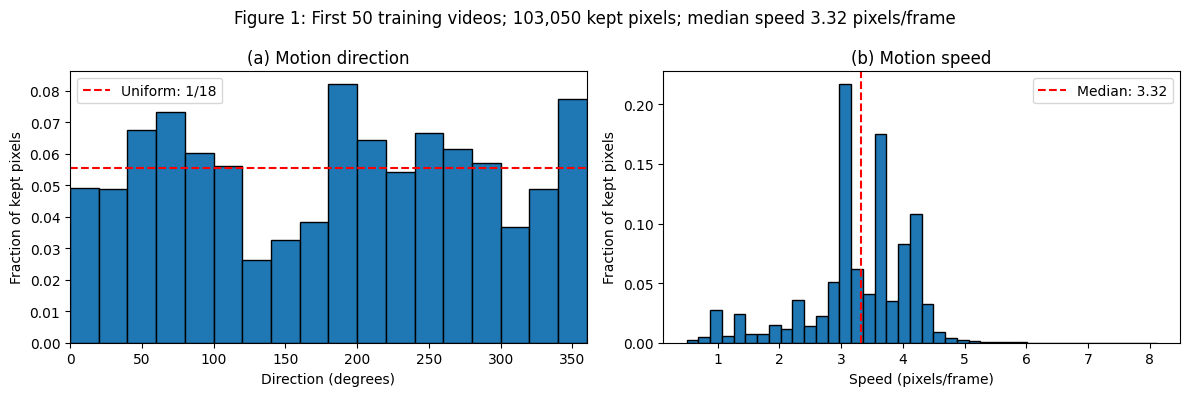

{'frame_pairs': 950, 'kept_pixels': 103050, 'median_speed': 3.317502498626709}


In [10]:
import cv2
import matplotlib.pyplot as plt

directions, speeds = [], []

for index in range(50):
    video = torch.as_tensor(raw[index]).numpy()[:, 0]  # uint8
    for s in range(19):
        prev = np.ascontiguousarray(video[s])
        nxt = np.ascontiguousarray(video[s + 1])

        flow = cv2.calcOpticalFlowFarneback(
            prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0
        )
        dx, dy = flow[..., 0], flow[..., 1]
        speed = np.sqrt(dx**2 + dy**2)
        keep = (prev > 51) & (nxt > 51) & (speed > 0.5)

        directions.append(
            (np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360)
        )
        speeds.append(speed[keep])

directions = np.concatenate(directions)
speeds = np.concatenate(speeds)
median_speed = float(np.median(speeds))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    directions, bins=np.arange(0, 361, 20),
    weights=np.ones(len(directions)) / len(directions),
    edgecolor="black"
)
axes[0].axhline(1 / 18, color="red", linestyle="--",
               label="Uniform: 1/18")
axes[0].set(
    xlabel="Direction (degrees)",
    ylabel="Fraction of kept pixels",
    title="(a) Motion direction",
    xlim=(0, 360)
)
axes[0].legend()

axes[1].hist(
    speeds, bins=40,
    weights=np.ones(len(speeds)) / len(speeds),
    edgecolor="black"
)
axes[1].axvline(median_speed, color="red", linestyle="--",
               label=f"Median: {median_speed:.3g}")
axes[1].set(
    xlabel="Speed (pixels/frame)",
    ylabel="Fraction of kept pixels",
    title="(b) Motion speed"
)
axes[1].legend()

fig.suptitle(
    f"Figure 1: First 50 training videos; "
    f"{len(speeds):,} kept pixels; median speed {median_speed:.3g} pixels/frame"
)
fig.tight_layout()
fig.savefig(ROOT / "figure1_motion_statistics.png",
            dpi=200, bbox_inches="tight")
plt.show()

stats = {
    "frame_pairs": 950,
    "kept_pixels": int(len(speeds)),
    "median_speed": median_speed
}
(ROOT / "figure1_statistics.json").write_text(json.dumps(stats, indent=2))
print(stats)

## Q1 design starting point
Use a causal temporal encoder per sensor, followed by directed river-graph message passing with learned lag weights, then station-specific heads predicting levels at issuance +60 minutes. Inputs include past S1–S4/T1 levels, past R1/R2 rainfall and actual reservoir releases, missingness masks and observation ages; encode announced future releases separately using only schedule versions available at issuance. Align on a ten-minute grid without using future values for imputation. Rainfall is projected to station/catchment features before combination; tributary T1 feeds S2 and downstream stations. The unmonitored tributary remains an explicit source of uncertainty.

This is an initial design, not the complete six-section Q1 answer. The final report needs its diagram, dimensions, assumptions, equations, operational handling and limitations.

## Still required for submission
Full Tables 1–6, Figures 1–6, GIFs, Q2.1–Q2.17, symmetrised B and D evaluation, all measured timings, Q1 report, public GitHub link on page one, AI prompts/outputs/edit disclosure and final PDF. Do not describe this starter as a complete assignment.


In [11]:
@torch.no_grad()
def baseline_stress_tests(seed):
    saved = torch.load(
        ROOT / f"A_seed{seed}" / "latest.pt",
        map_location="cpu", weights_only=False
    )
    assert saved["epoch"] == 30
    model = Forecaster().to(device)
    model.load_state_dict(saved["model"])
    model.eval()

    results = {}
    per_video = {}

    for k in (1, 2, 3):
        records = {
            name: [] for name in ("A", "Blank", "Copy-last")
        }
        gaps = {"CM": [], "EM": [], "CR": [], "ER": []}

        loader = DataLoader(
            Windows(range(9000, 10000), evaluation=True, k=k),
            batch_size=32, shuffle=False
        )

        for xx, yy, mask in loader:
            xx, yy, mask = (
                xx.to(device), yy.to(device), mask.to(device)
            )
            pred = model(xx)
            predictions = {
                "A": pred,
                "Blank": torch.zeros_like(yy),
                "Copy-last": xx[:, -1:].expand_as(yy)
            }

            for name, pp in predictions.items():
                mse = (pp - yy).square().mean((2, 3, 4))
                records[name].append(mse.cpu())

            if k == 1:
                for label, a, mirror in (
                    ("M", 0, True), ("R", 1, False)
                ):
                    transformed_pred = model(transform(xx, a, mirror))
                    transformed_original = transform(pred, a, mirror)
                    transformed_target = transform(yy, a, mirror)

                    gaps["C" + label].append(
                        (transformed_pred - transformed_original)
                        .square().mean((1, 2, 3, 4)).cpu()
                    )
                    gaps["E" + label].append(
                        (transformed_pred - transformed_target)
                        .square().mean((1, 2, 3, 4)).cpu()
                    )

        results[f"{k}x"] = {}
        for name, batches in records.items():
            mse = torch.cat(batches)
            entry = {"E2": mse[:, :2].mean().item()}
            if k in (1, 2):
                entry["E5"] = mse.mean().item()
            results[f"{k}x"][name] = entry

        if k == 1:
            for key, batches in gaps.items():
                values = torch.cat(batches)
                results["1x"]["A"][key] = values.mean().item()
                per_video[key] = values.numpy()

            # These references commute exactly with mirror and rotation.
            for name in ("Blank", "Copy-last"):
                error = results["1x"][name]["E5"]
                results["1x"][name].update(
                    CM=0.0, EM=error, CR=0.0, ER=error
                )

    (ROOT / f"baseline_stress_seed{seed}.json").write_text(
        json.dumps(results, indent=2)
    )
    np.savez(
        ROOT / f"baseline_per_video_seed{seed}.npz",
        **per_video
    )
    print(f"\nSEED {seed}")
    print(json.dumps(results, indent=2))
    return results

stress_seed0 = baseline_stress_tests(0)
stress_seed1 = baseline_stress_tests(1)


SEED 0
{
  "1x": {
    "A": {
      "E2": 0.01919330283999443,
      "E5": 0.022762369364500046,
      "CM": 0.001810079556889832,
      "EM": 0.02338532730937004,
      "CR": 0.0029045632109045982,
      "ER": 0.02427506260573864
    },
    "Blank": {
      "E2": 0.04258999601006508,
      "E5": 0.042563606053590775,
      "CM": 0.0,
      "EM": 0.042563606053590775,
      "CR": 0.0,
      "ER": 0.042563606053590775
    },
    "Copy-last": {
      "E2": 0.05479172617197037,
      "E5": 0.06408222019672394,
      "CM": 0.0,
      "EM": 0.06408222019672394,
      "CR": 0.0,
      "ER": 0.06408222019672394
    }
  },
  "2x": {
    "A": {
      "E2": 0.04461663216352463,
      "E5": 0.048130281269550323
    },
    "Blank": {
      "E2": 0.0425109826028347,
      "E5": 0.04254010692238808
    },
    "Copy-last": {
      "E2": 0.06606845557689667,
      "E5": 0.07188227772712708
    }
  },
  "3x": {
    "A": {
      "E2": 0.05170492082834244
    },
    "Blank": {
      "E2": 0.042585428804

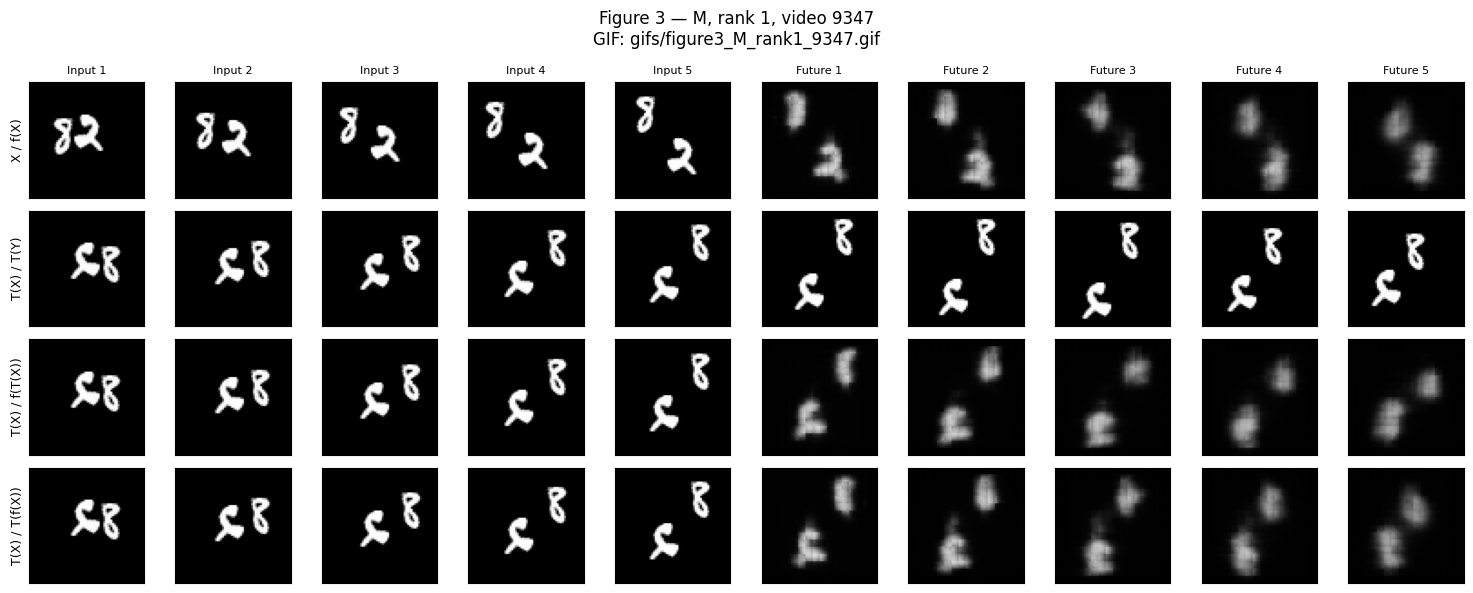

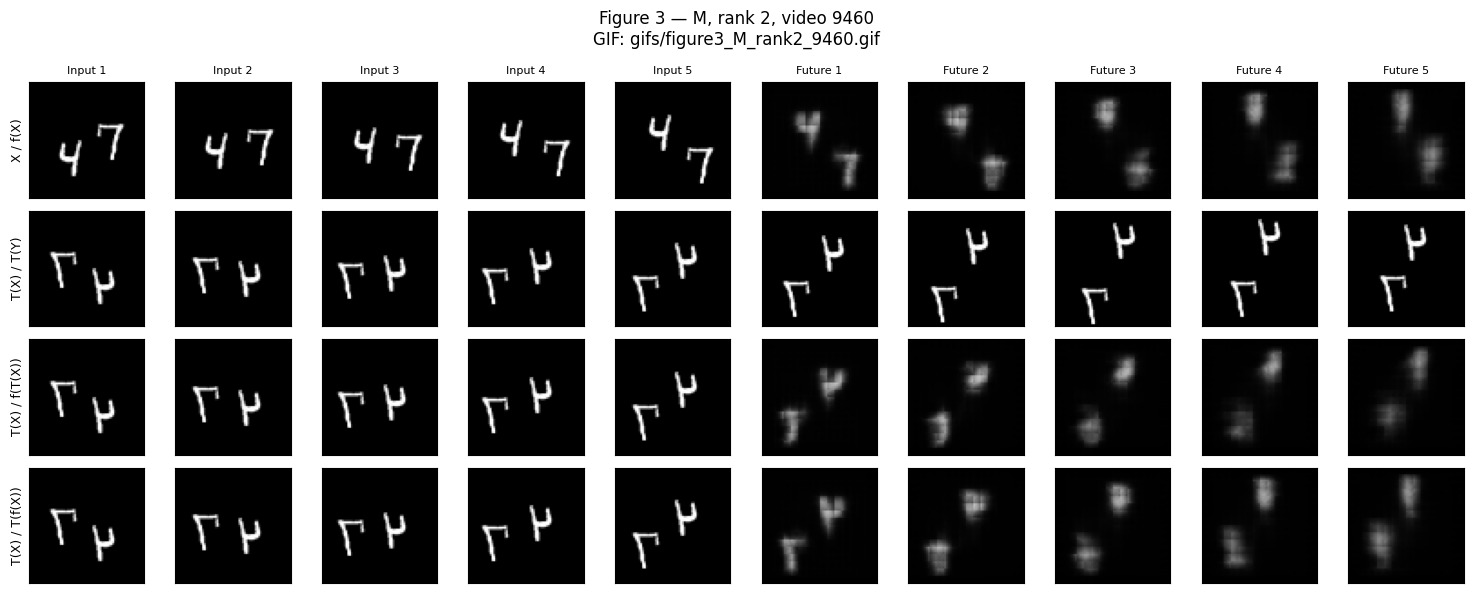

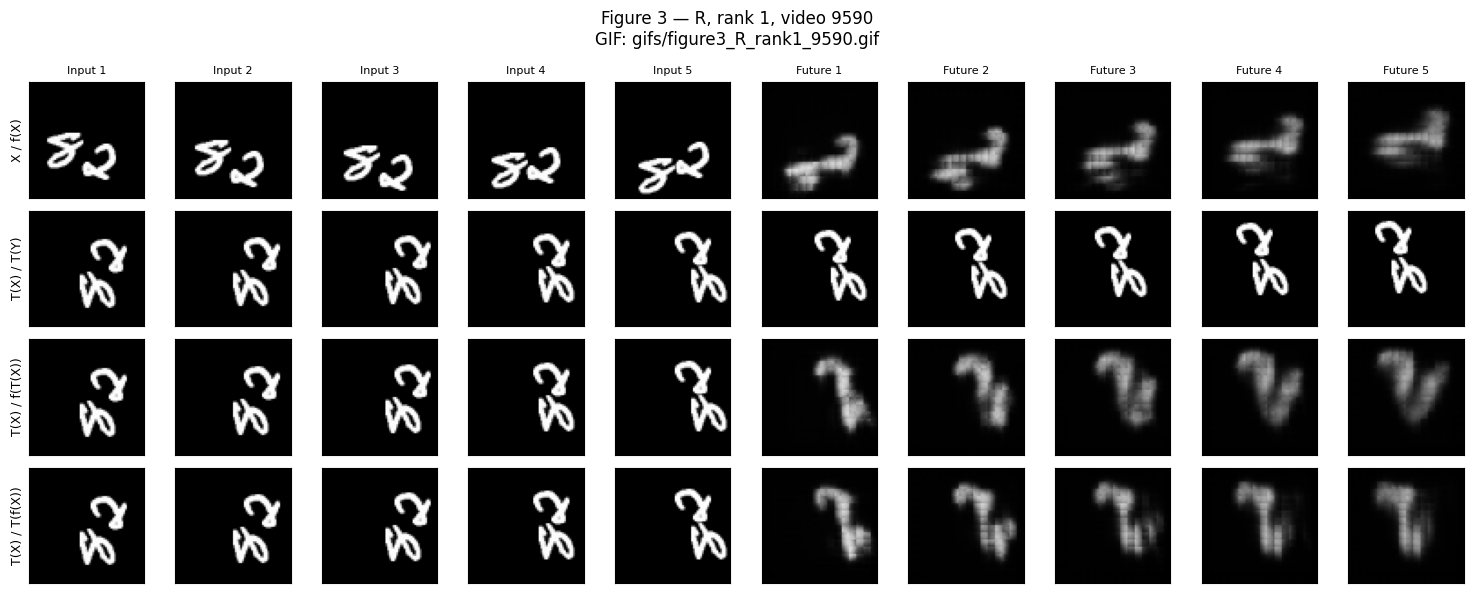

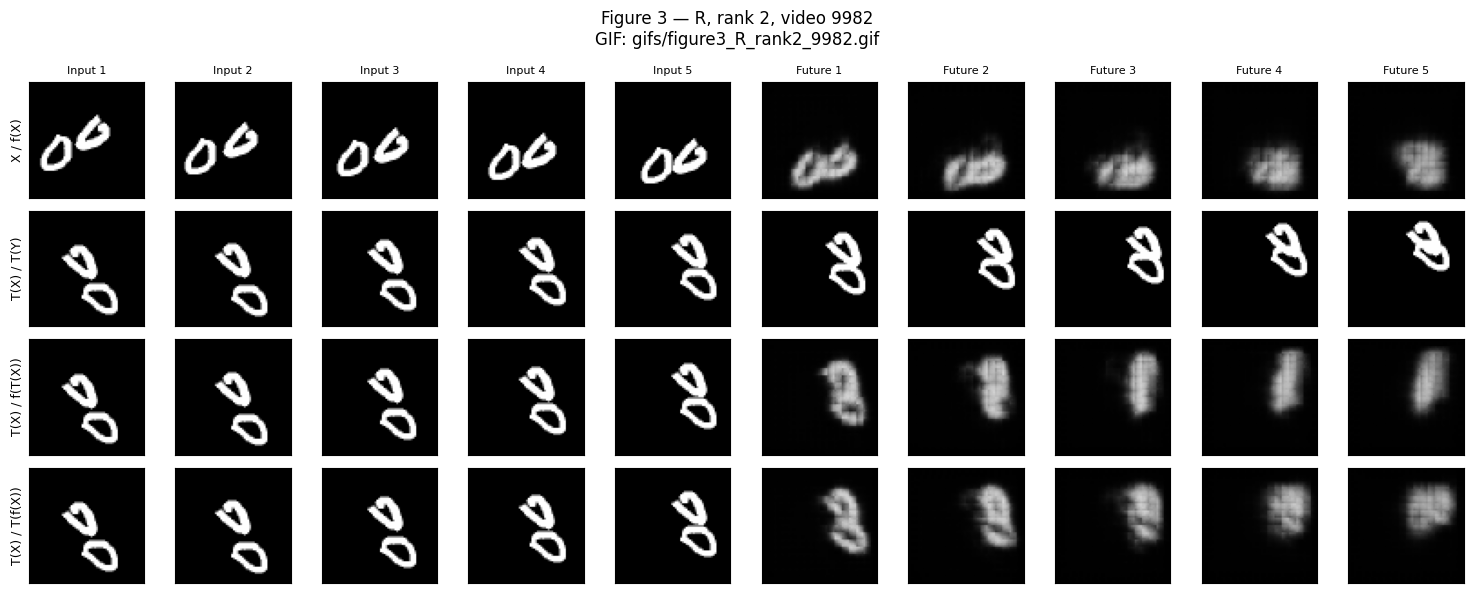

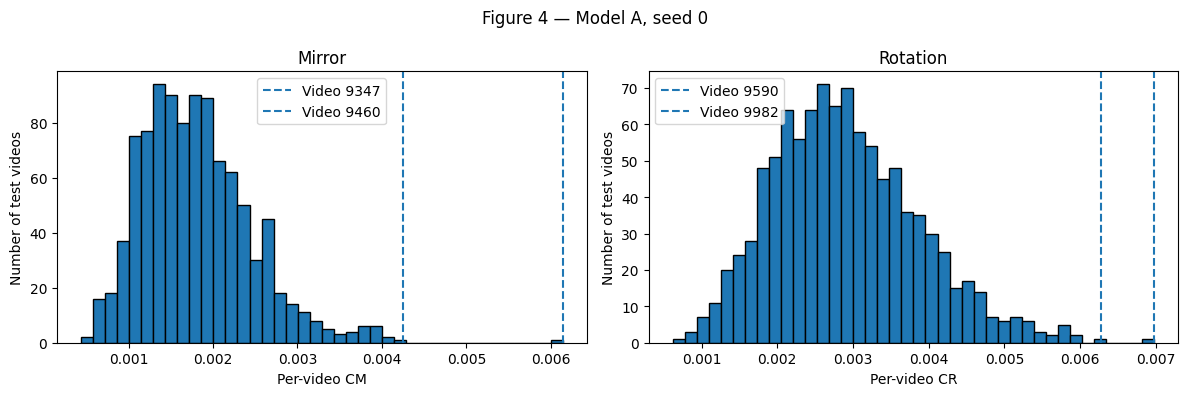

Selected test videos: {'M': [9347, 9460], 'R': [9590, 9982]}
Figures and GIFs saved to: /content/drive/MyDrive/25280097_AI651_PA2


In [12]:
from PIL import Image

# Load seed-0 baseline.
saved = torch.load(
    ROOT / "A_seed0" / "latest.pt",
    map_location="cpu", weights_only=False
)
model_A = Forecaster().to(device)
model_A.load_state_dict(saved["model"])
model_A.eval()

gaps = np.load(ROOT / "baseline_per_video_seed0.npz")
selected = {}
gif_dir = ROOT / "gifs"
gif_dir.mkdir(exist_ok=True)

for label, a, mirror in (("M", 0, True), ("R", 1, False)):
    # Positions 0–999 correspond to dataset indices 9000–9999.
    top = np.argsort(gaps["C" + label])[-2:][::-1]
    selected[label] = [int(i + 9000) for i in top]

    for rank, position in enumerate(top, start=1):
        video_id = int(position + 9000)
        video = torch.as_tensor(raw[video_id]).float() / 255
        xx, yy, _ = window(video, k=1, t=1)
        xx = xx.unsqueeze(0).to(device)

        with torch.no_grad():
            original_pred = model_A(xx)[0].cpu()
            transformed_pred = model_A(
                transform(xx, a, mirror)
            )[0].cpu()

        original_input = xx[0].cpu()
        transformed_input = transform(original_input, a, mirror)
        transformed_truth = transform(yy, a, mirror)
        transformed_original_pred = transform(
            original_pred, a, mirror
        )

        rows = [
            torch.cat((original_input, original_pred)),
            torch.cat((transformed_input, transformed_truth)),
            torch.cat((transformed_input, transformed_pred)),
            torch.cat((transformed_input, transformed_original_pred))
        ]
        row_labels = [
            "X / f(X)", "T(X) / T(Y)",
            "T(X) / f(T(X))", "T(X) / T(f(X))"
        ]

        fig, axes = plt.subplots(4, 10, figsize=(15, 6))
        for r in range(4):
            for c in range(10):
                axes[r, c].imshow(
                    rows[r][c, 0], cmap="gray", vmin=0, vmax=1
                )
                axes[r, c].set_xticks([])
                axes[r, c].set_yticks([])
                if r == 0:
                    axes[r, c].set_title(
                        f"Input {c+1}" if c < 5 else f"Future {c-4}",
                        fontsize=8
                    )
            axes[r, 0].set_ylabel(row_labels[r], fontsize=9)

        gif_path = gif_dir / f"figure3_{label}_rank{rank}_{video_id}.gif"
        fig.suptitle(
            f"Figure 3 — {label}, rank {rank}, video {video_id}\n"
            f"GIF: gifs/{gif_path.name}"
        )
        fig.tight_layout()
        fig.savefig(
            ROOT / f"figure3_{label}_rank{rank}_{video_id}.png",
            dpi=160, bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

        # Four rows: last input frame beside each forecast horizon.
        animations = []
        for h in range(5):
            strips = []
            for r in range(4):
                pair = torch.cat(
                    (rows[r][4, 0], rows[r][5+h, 0]), dim=1
                )
                strips.append(pair)
            canvas = torch.cat(strips, dim=0)
            pixels = (canvas.clamp(0, 1).numpy() * 255).astype(np.uint8)
            animations.append(Image.fromarray(pixels).resize((256, 512)))

        animations[0].save(
            gif_path, save_all=True,
            append_images=animations[1:],
            duration=500, loop=0
        )

# Figure 4: consistency-gap distributions, with selected videos marked.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, label in zip(axes, ("M", "R")):
    values = gaps["C" + label]
    ax.hist(values, bins=40, edgecolor="black")
    for video_id in selected[label]:
        ax.axvline(
            values[video_id - 9000],
            linestyle="--", label=f"Video {video_id}"
        )
    ax.set(
        xlabel=f"Per-video C{label}",
        ylabel="Number of test videos",
        title="Mirror" if label == "M" else "Rotation"
    )
    ax.legend()

fig.suptitle("Figure 4 — Model A, seed 0")
fig.tight_layout()
fig.savefig(ROOT / "figure4_gap_histograms.png", dpi=200)
plt.show()
plt.close(fig)

(ROOT / "figure3_selected_videos.json").write_text(
    json.dumps(selected, indent=2)
)
print("Selected test videos:", selected)
print("Figures and GIFs saved to:", ROOT)

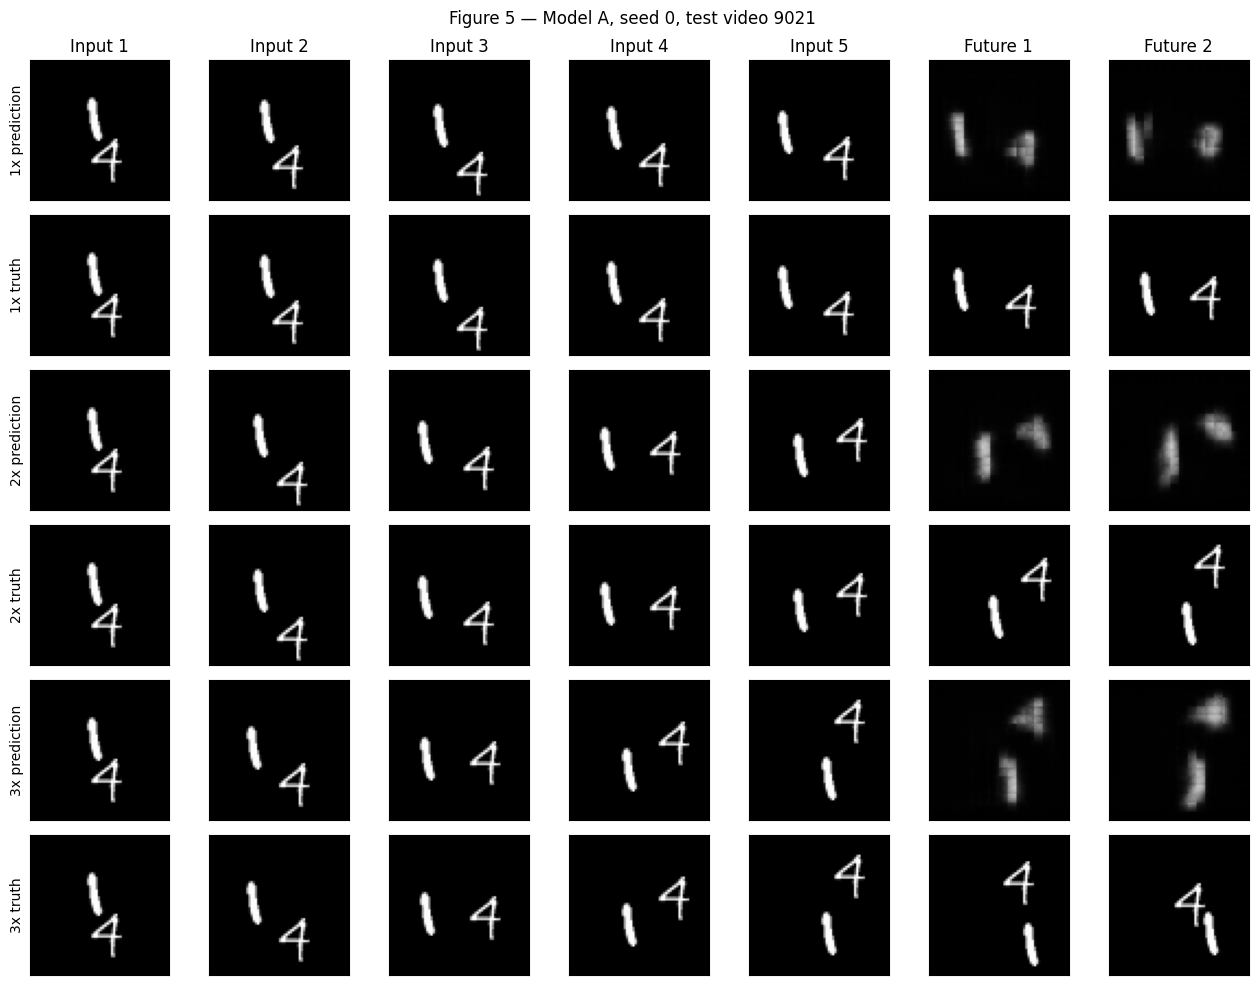

Selected video: 9021


In [13]:
# Find a candidate with two separate foreground components
# in every displayed true frame. Visually confirm no overlap.
displayed = sorted(set(
    [0, 1, 2, 3, 4, 5, 6] +
    [0, 2, 4, 6, 8, 10, 12] +
    [0, 3, 6, 9, 12, 15, 18]
))

def two_separate_components(frame):
    binary = (frame > 0.2).astype(np.uint8)
    _, _, stats, _ = cv2.connectedComponentsWithStats(binary, 8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    return np.count_nonzero(areas >= 8) == 2

speed_video_id = None
for video_id in range(9000, 10000):
    video = torch.as_tensor(raw[video_id]).float() / 255
    if all(two_separate_components(video[f, 0].numpy())
           for f in displayed):
        speed_video_id = video_id
        break

assert speed_video_id is not None, "No candidate found; select visually."
video = torch.as_tensor(raw[speed_video_id]).float() / 255

fig, axes = plt.subplots(6, 7, figsize=(13, 10))

for block, k in enumerate((1, 2, 3)):
    xx, yy, _ = window(video, k=k, t=1)
    with torch.no_grad():
        pred = model_A(xx.unsqueeze(0).to(device))[0].cpu()

    rows = [
        torch.cat((xx, pred[:2])),
        torch.cat((xx, yy[:2]))
    ]
    for r, frames in enumerate(rows):
        row = 2 * block + r
        for c in range(7):
            axes[row, c].imshow(
                frames[c, 0], cmap="gray", vmin=0, vmax=1
            )
            axes[row, c].set_xticks([])
            axes[row, c].set_yticks([])
            if row == 0:
                axes[row, c].set_title(
                    f"Input {c+1}" if c < 5 else f"Future {c-4}"
                )
        axes[row, 0].set_ylabel(
            f"{k}x prediction" if r == 0 else f"{k}x truth"
        )

fig.suptitle(
    f"Figure 5 — Model A, seed 0, test video {speed_video_id}"
)
fig.tight_layout()
fig.savefig(ROOT / "figure5_speed_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()

(ROOT / "figure5_selected_video.json").write_text(
    json.dumps({"video_id": speed_video_id}, indent=2)
)
print("Selected video:", speed_video_id)

In [14]:
for name in ("B", "C", "D"):
    for seed in (0, 1):
        train(name, seed)

B seed 0 | 1/30 | MSE 0.046132 | 13.1s/epoch | this run ~6.3 min left
B seed 0 | 2/30 | MSE 0.039698 | 13.1s/epoch | this run ~6.1 min left
B seed 0 | 3/30 | MSE 0.038702 | 12.6s/epoch | this run ~5.8 min left
B seed 0 | 4/30 | MSE 0.037261 | 12.5s/epoch | this run ~5.6 min left
B seed 0 | 5/30 | MSE 0.035423 | 12.5s/epoch | this run ~5.3 min left
B seed 0 | 6/30 | MSE 0.033683 | 12.6s/epoch | this run ~5.1 min left
B seed 0 | 7/30 | MSE 0.032330 | 13.0s/epoch | this run ~4.9 min left
B seed 0 | 8/30 | MSE 0.031252 | 12.9s/epoch | this run ~4.7 min left
B seed 0 | 9/30 | MSE 0.030521 | 12.8s/epoch | this run ~4.5 min left
B seed 0 | 10/30 | MSE 0.029798 | 12.8s/epoch | this run ~4.3 min left
B seed 0 | 11/30 | MSE 0.029361 | 12.7s/epoch | this run ~4.0 min left
B seed 0 | 12/30 | MSE 0.028929 | 12.7s/epoch | this run ~3.8 min left
B seed 0 | 13/30 | MSE 0.028622 | 12.7s/epoch | this run ~3.6 min left
B seed 0 | 14/30 | MSE 0.028123 | 12.8s/epoch | this run ~3.4 min left
B seed 0 | 15/3

In [15]:
@torch.no_grad()
def symmetrised_predict(model, xx):
    total = None
    for a in range(4):
        for mirror in (False, True):
            pred = model(transform(xx, a, mirror))
            pred = inverse_transform(pred, a, mirror)
            total = pred if total is None else total + pred
    return total / 8


@torch.no_grad()
def evaluate_model(name, seed, wrapped=False):
    saved = torch.load(
        ROOT / f"{name}_seed{seed}" / "latest.pt",
        map_location="cpu", weights_only=False
    )
    assert saved["epoch"] == 30

    model = Forecaster(name).to(device)
    model.load_state_dict(saved["model"])
    model.eval()

    def predict(xx):
        return (
            symmetrised_predict(model, xx)
            if wrapped else model(xx)
        )

    result = {
        "parameters": count(model),
        "train_seconds_per_epoch": float(np.mean(
            [row["seconds"] for row in saved["history"]]
        )),
        "hardware": torch.cuda.get_device_name(0)
    }
    inference_seconds = 0.0

    for k in (1, 2, 3):
        errors = []
        consistency = {"CM": [], "EM": [], "CR": [], "ER": []}
        loader = DataLoader(
            Windows(range(9000, 10000), evaluation=True, k=k),
            batch_size=32, shuffle=False
        )

        for batch_index, (xx, yy, mask) in enumerate(loader):
            xx = xx.to(device)
            yy = yy.to(device)

            if k == 1:
                # Warm up once; exclude warmup and data transfers.
                if batch_index == 0:
                    _ = predict(xx)
                torch.cuda.synchronize()
                started = time.perf_counter()

            pred = predict(xx)

            if k == 1:
                torch.cuda.synchronize()
                inference_seconds += time.perf_counter() - started

            errors.append(
                (pred - yy).square().mean((2, 3, 4)).cpu()
            )

            if k == 1:
                for label, a, mirror in (
                    ("M", 0, True), ("R", 1, False)
                ):
                    transformed_pred = predict(transform(xx, a, mirror))
                    consistency["C" + label].append(
                        (
                            transformed_pred -
                            transform(pred, a, mirror)
                        ).square().mean((1, 2, 3, 4)).cpu()
                    )
                    consistency["E" + label].append(
                        (
                            transformed_pred -
                            transform(yy, a, mirror)
                        ).square().mean((1, 2, 3, 4)).cpu()
                    )

        mse = torch.cat(errors)
        result[f"E2_{k}x"] = mse[:, :2].mean().item()

        if k == 1:
            result["E5_1x"] = mse.mean().item()
            for metric, batches in consistency.items():
                result[metric] = torch.cat(batches).mean().item()

    result["inference_seconds_1000"] = inference_seconds

    label = f"sym_{name}" if wrapped else name
    path = ROOT / f"evaluation_{label}_seed{seed}.json"
    path.write_text(json.dumps(result, indent=2))
    print(f"Completed {label}, seed {seed}", flush=True)

    del model
    torch.cuda.empty_cache()
    return result


evaluations = {}

# Table 5: models A–D.
for name in ("A", "B", "C", "D"):
    evaluations[name] = [
        evaluate_model(name, seed) for seed in (0, 1)
    ]

# Table 6: symmetry wrappers; symmetrised D is the final model.
for name in ("B", "D"):
    evaluations[f"sym_{name}"] = [
        evaluate_model(name, seed, wrapped=True)
        for seed in (0, 1)
    ]

(ROOT / "tables5_6_all_results.json").write_text(
    json.dumps(evaluations, indent=2)
)

metrics = [
    "E5_1x", "CM", "EM", "CR", "ER",
    "E2_1x", "E2_2x", "E2_3x",
    "parameters", "train_seconds_per_epoch",
    "inference_seconds_1000"
]

for name, runs in evaluations.items():
    print(f"\n{name}: mean (seed 0, seed 1)")
    for metric in metrics:
        v0, v1 = runs[0][metric], runs[1][metric]
        print(
            f"{metric}: {(v0 + v1)/2:.6g} "
            f"({v0:.6g}, {v1:.6g})"
        )

Completed A, seed 0
Completed A, seed 1
Completed B, seed 0
Completed B, seed 1
Completed C, seed 0
Completed C, seed 1
Completed D, seed 0
Completed D, seed 1
Completed sym_B, seed 0
Completed sym_B, seed 1
Completed sym_D, seed 0
Completed sym_D, seed 1

A: mean (seed 0, seed 1)
E5_1x: 0.022152 (0.0227624, 0.0215415)
CM: 0.00192131 (0.00181008, 0.00203255)
EM: 0.0228644 (0.0233853, 0.0223435)
CR: 0.00316505 (0.00290456, 0.00342553)
ER: 0.0239274 (0.0242751, 0.0235797)
E2_1x: 0.0185504 (0.0191933, 0.0179075)
E2_2x: 0.0449528 (0.0446166, 0.0452889)
E2_3x: 0.0521733 (0.0517049, 0.0526416)
parameters: 480784 (480784, 480784)
train_seconds_per_epoch: 13.1224 (13.0819, 13.1628)
inference_seconds_1000: 0.428972 (0.436868, 0.421076)

B: mean (seed 0, seed 1)
E5_1x: 0.0223221 (0.0224829, 0.0221614)
CM: 0.00160694 (0.00149999, 0.00171388)
EM: 0.0222693 (0.0224415, 0.0220971)
CR: 0.00160554 (0.00152151, 0.00168957)
ER: 0.0223274 (0.0224919, 0.022163)
E2_1x: 0.0185273 (0.0185992, 0.0184555)
E2_2

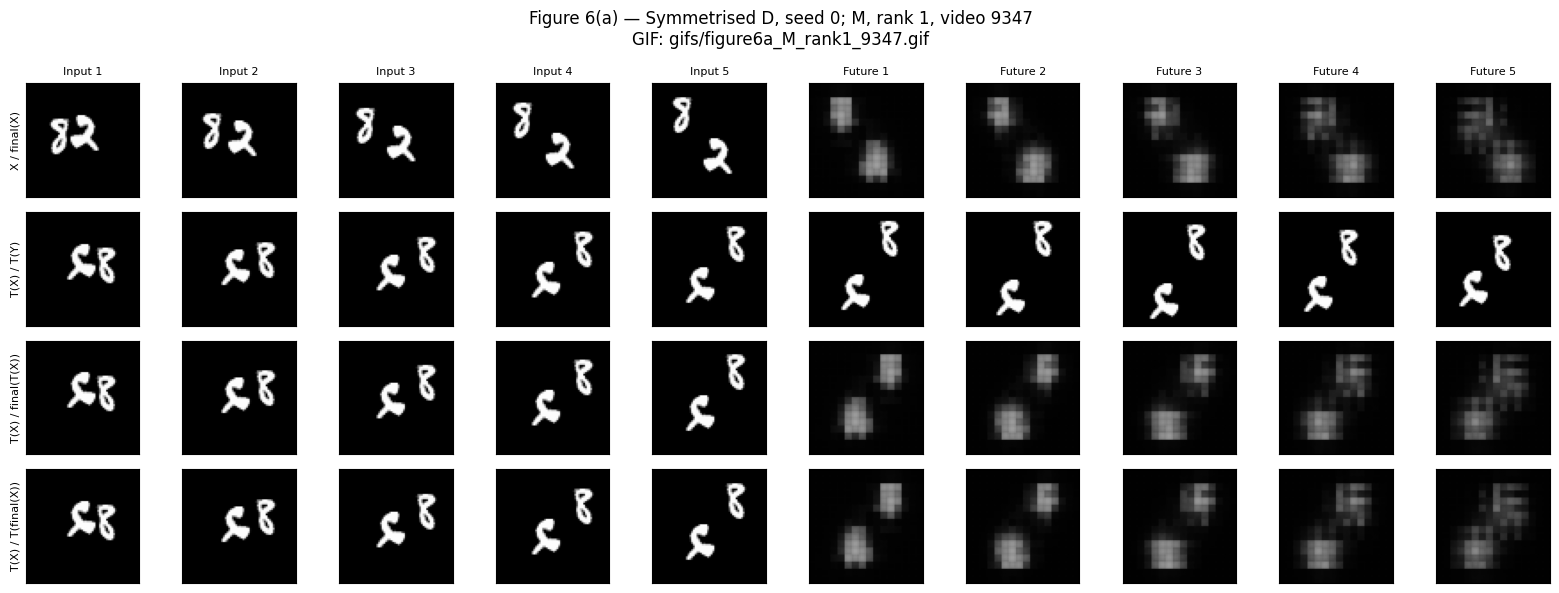

M, video 9347: consistency MSE = 8.929e-17


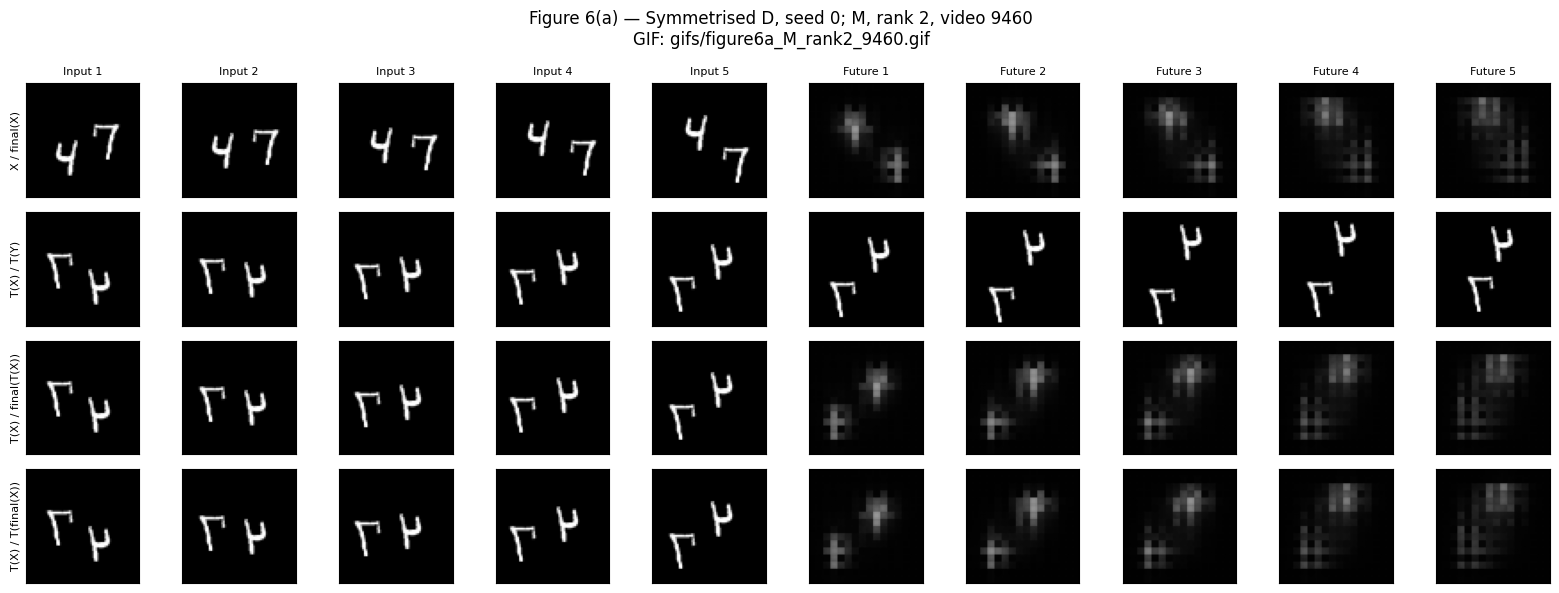

M, video 9460: consistency MSE = 3.604e-17


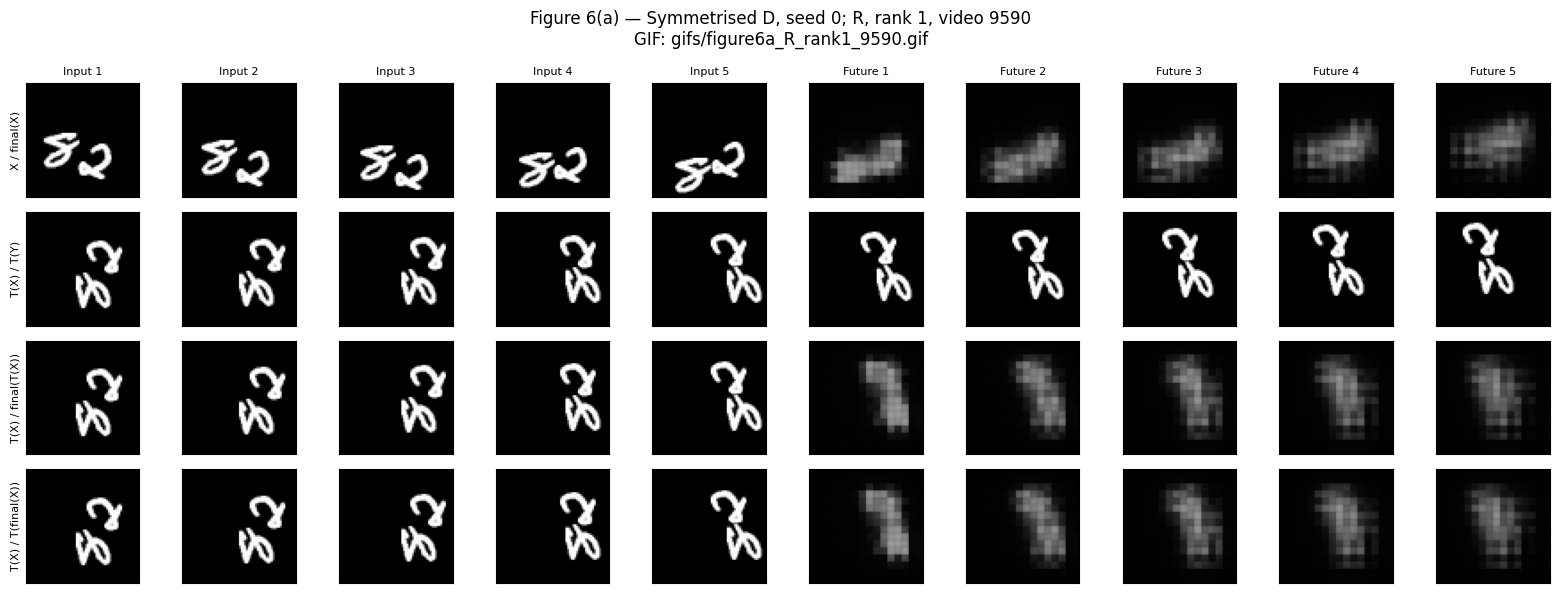

R, video 9590: consistency MSE = 1.022e-16


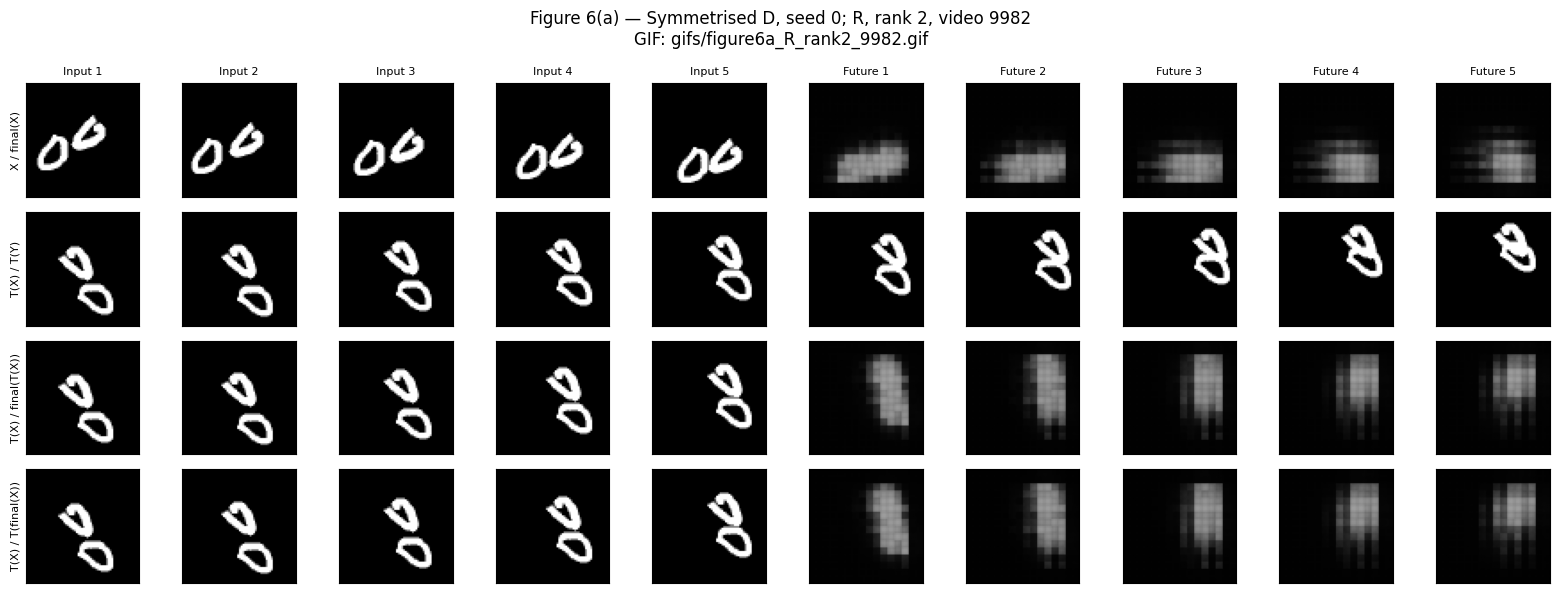

R, video 9982: consistency MSE = 1.330e-16


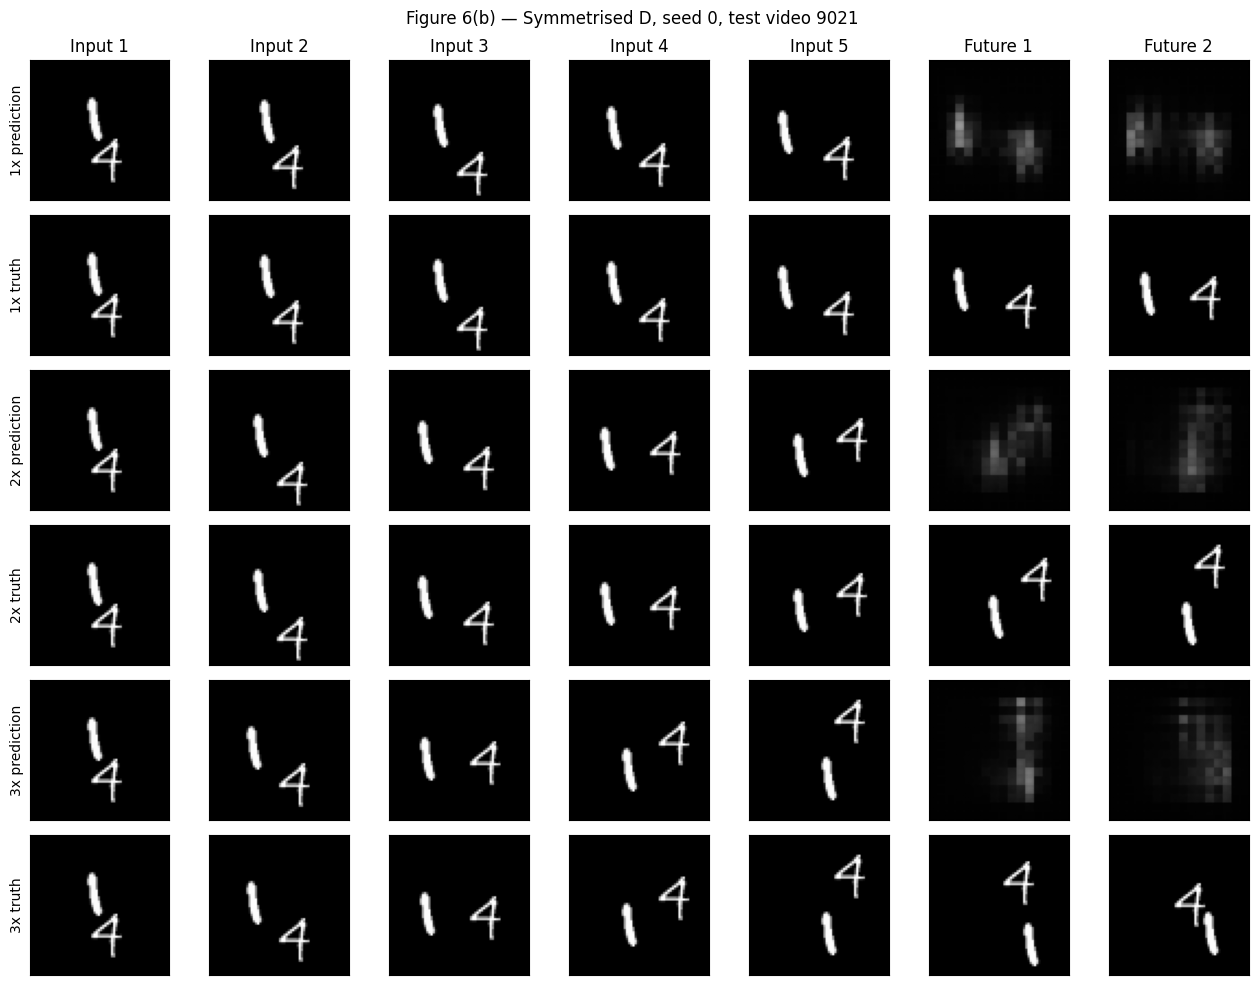

Figure 6 panels and GIFs saved to: /content/drive/MyDrive/25280097_AI651_PA2


In [16]:
from PIL import Image, ImageDraw

# Final model: symmetrised D, seed 0.
saved = torch.load(
    ROOT / "D_seed0" / "latest.pt",
    map_location="cpu", weights_only=False
)
assert saved["epoch"] == 30

final_base = Forecaster("D").to(device)
final_base.load_state_dict(saved["model"])
final_base.eval()

@torch.no_grad()
def final_predict(xx):
    return symmetrised_predict(final_base, xx)

selected = json.loads(
    (ROOT / "figure3_selected_videos.json").read_text()
)
speed_video_id = json.loads(
    (ROOT / "figure5_selected_video.json").read_text()
)["video_id"]

gif_dir = ROOT / "gifs"
gif_dir.mkdir(exist_ok=True)

# Figure 6(a): same four cases as Figure 3.
for label, a, mirror in (("M", 0, True), ("R", 1, False)):
    for rank, video_id in enumerate(selected[label], start=1):
        video = torch.as_tensor(raw[video_id]).float() / 255
        xx, yy, _ = window(video, k=1, t=1)
        batch = xx.unsqueeze(0).to(device)

        pred = final_predict(batch)[0].cpu()
        transformed_pred = final_predict(
            transform(batch, a, mirror)
        )[0].cpu()

        tx = transform(xx, a, mirror)
        ty = transform(yy, a, mirror)
        tp = transform(pred, a, mirror)

        rows = [
            torch.cat((xx, pred)),
            torch.cat((tx, ty)),
            torch.cat((tx, transformed_pred)),
            torch.cat((tx, tp))
        ]
        row_labels = [
            "X / final(X)",
            "T(X) / T(Y)",
            "T(X) / final(T(X))",
            "T(X) / T(final(X))"
        ]

        gif_path = (
            gif_dir / f"figure6a_{label}_rank{rank}_{video_id}.gif"
        )

        fig, axes = plt.subplots(4, 10, figsize=(16, 6))
        for r in range(4):
            for c in range(10):
                axes[r, c].imshow(
                    rows[r][c, 0], cmap="gray", vmin=0, vmax=1
                )
                axes[r, c].set_xticks([])
                axes[r, c].set_yticks([])
                if r == 0:
                    axes[r, c].set_title(
                        f"Input {c+1}" if c < 5 else f"Future {c-4}",
                        fontsize=8
                    )
            axes[r, 0].set_ylabel(row_labels[r], fontsize=8)

        fig.suptitle(
            f"Figure 6(a) — Symmetrised D, seed 0; "
            f"{label}, rank {rank}, video {video_id}\n"
            f"GIF: gifs/{gif_path.name}"
        )
        fig.tight_layout()
        fig.savefig(
            ROOT / f"figure6a_{label}_rank{rank}_{video_id}.png",
            dpi=200, bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

        # Animated panel: last input beside the current future.
        animations = []
        scale = 3
        left_margin = 180
        header = 30

        for h in range(5):
            canvas = Image.new(
                "RGB",
                (left_margin + 128 * scale, header + 4 * 64 * scale),
                "white"
            )
            draw = ImageDraw.Draw(canvas)
            draw.text(
                (left_margin, 8),
                f"Last input       Future horizon {h+1}",
                fill="black"
            )

            for r in range(4):
                pair = torch.cat(
                    (rows[r][4, 0], rows[r][5+h, 0]), dim=1
                )
                pixels = (
                    pair.clamp(0, 1).numpy() * 255
                ).astype(np.uint8)
                panel = Image.fromarray(pixels).resize(
                    (128 * scale, 64 * scale),
                    Image.Resampling.NEAREST
                ).convert("RGB")
                y = header + r * 64 * scale
                canvas.paste(panel, (left_margin, y))
                draw.text(
                    (5, y + 25), row_labels[r], fill="black"
                )

            animations.append(canvas)

        animations[0].save(
            gif_path,
            save_all=True,
            append_images=animations[1:],
            duration=500,
            loop=0
        )

        gap = (transformed_pred - tp).square().mean().item()
        print(f"{label}, video {video_id}: consistency MSE = {gap:.3e}")

# Figure 6(b): same video and speed windows as Figure 5.
video = torch.as_tensor(raw[speed_video_id]).float() / 255
fig, axes = plt.subplots(6, 7, figsize=(13, 10))

for block, k in enumerate((1, 2, 3)):
    xx, yy, _ = window(video, k=k, t=1)
    pred = final_predict(xx.unsqueeze(0).to(device))[0].cpu()

    rows = [
        torch.cat((xx, pred[:2])),
        torch.cat((xx, yy[:2]))
    ]

    for r, frames in enumerate(rows):
        row = 2 * block + r
        for c in range(7):
            axes[row, c].imshow(
                frames[c, 0], cmap="gray", vmin=0, vmax=1
            )
            axes[row, c].set_xticks([])
            axes[row, c].set_yticks([])
            if row == 0:
                axes[row, c].set_title(
                    f"Input {c+1}" if c < 5 else f"Future {c-4}"
                )
        axes[row, 0].set_ylabel(
            f"{k}x prediction" if r == 0 else f"{k}x truth"
        )

fig.suptitle(
    f"Figure 6(b) — Symmetrised D, seed 0, "
    f"test video {speed_video_id}"
)
fig.tight_layout()
fig.savefig(
    ROOT / "figure6b_speed_comparison.png",
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Figure 6 panels and GIFs saved to:", ROOT)

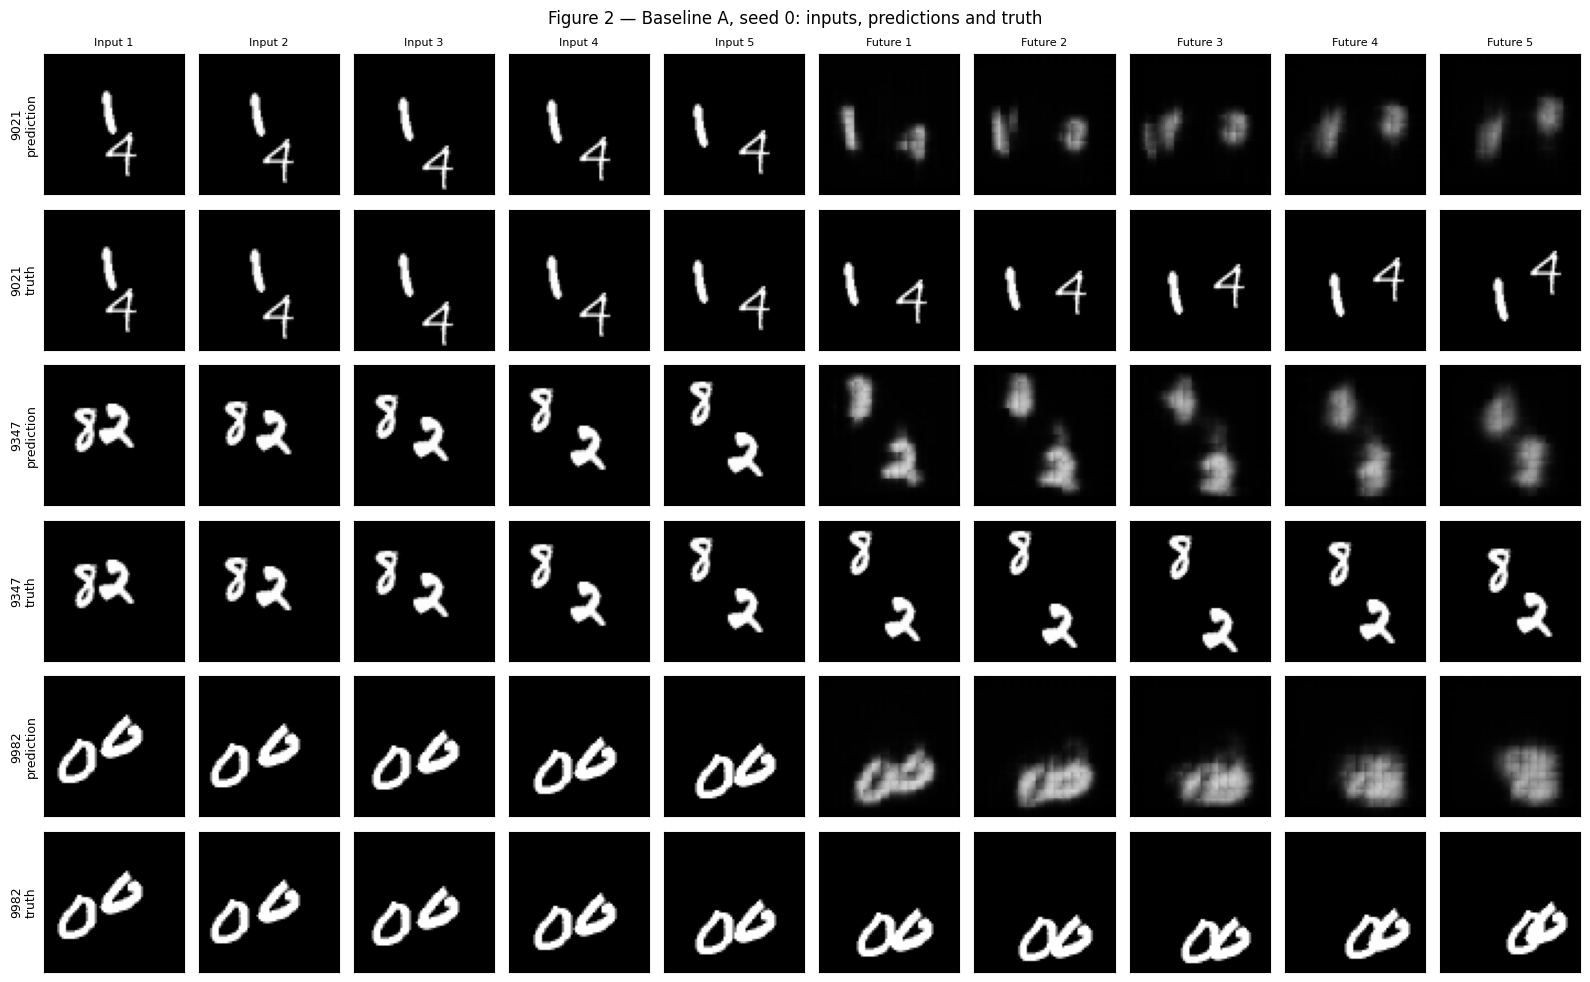

Figure 2 saved.


In [17]:
# Figure 2: three baseline examples, seed 0.
# Visually confirm that at least one example contains overlapping digits.
example_ids = [9021, 9347, 9982]

saved = torch.load(
    ROOT / "A_seed0" / "latest.pt",
    map_location="cpu", weights_only=False
)
baseline = Forecaster("A").to(device)
baseline.load_state_dict(saved["model"])
baseline.eval()

fig, axes = plt.subplots(6, 10, figsize=(16, 10))

for example, video_id in enumerate(example_ids):
    video = torch.as_tensor(raw[video_id]).float() / 255
    xx, yy, _ = window(video, k=1, t=1)

    with torch.no_grad():
        pred = baseline(xx.unsqueeze(0).to(device))[0].cpu()

    rows = [
        torch.cat((xx, pred)),
        torch.cat((xx, yy))
    ]

    for r, frames in enumerate(rows):
        row = 2 * example + r
        for c in range(10):
            axes[row, c].imshow(
                frames[c, 0], cmap="gray", vmin=0, vmax=1
            )
            axes[row, c].set_xticks([])
            axes[row, c].set_yticks([])
            if row == 0:
                axes[row, c].set_title(
                    f"Input {c+1}" if c < 5 else f"Future {c-4}",
                    fontsize=8
                )

        axes[row, 0].set_ylabel(
            f"{video_id}\nprediction" if r == 0
            else f"{video_id}\ntruth",
            fontsize=9
        )

fig.suptitle("Figure 2 — Baseline A, seed 0: inputs, predictions and truth")
fig.tight_layout()
fig.savefig(
    ROOT / "figure2_baseline_examples.png",
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

(ROOT / "figure2_selected_videos.json").write_text(
    json.dumps({"video_ids": example_ids}, indent=2)
)
print("Figure 2 saved.")


In [18]:
import zipfile
from google.colab import files

zip_path = Path("/content/25280097_AI651_PA2_results.zip")

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(ROOT.rglob("*")):
        if path.is_file() and path.suffix.lower() in {
            ".json", ".png", ".gif", ".npz"
        }:
            archive.write(path, arcname=str(path.relative_to(ROOT)))

print(f"Results ZIP: {zip_path.stat().st_size / 1e6:.1f} MB")
files.download(str(zip_path))

Results ZIP: 3.4 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>